# Tarea 4: elementos difractivos y deconvolución

**Fotografía Computacional - INF-449, Universidad Técnica Federico Santa María**

Cuaderno local para ejecutar y documentar la solución. Usa el dataset McMaster de `tareas/tarea-04/McMaster` (18 imágenes) y los resultados guardados en esta carpeta. Configuracion principal: `256x256`, `sigma=0`, `tau=0.01`, `K=25`. El experimento completo es opcional y regenera métricas, figuras y barridos.


## 1. Modelo y fuentes

Para cada longitud de onda (650, 550 y 450 nm para R, G y B), se calcula $h_c=|\mathcal F\{A\exp(i\lambda_0\phi/\lambda)\}|^2$. La fase cúbica se combina con los modos de Zernike $Z_4,Z_5,Z_6,Z_7,Z_8,Z_{11}$ de Noll, con coeficientes especificados en `homework4.py`. La escena atraviesa una PSF por canal, el mosaico Bayer RGGB, demosaicking y reconstrucción.

La guía pide Wiener y Richardson-Lucy propios, su comparación con `skimage.restoration` y PSNR, SSIM y SAM sobre McMaster. Se resuelve ademas el modelo regularizado directamente sobre Bayer. Para teoría, consulta *Computational Optical Imaging*: cap. 2, sec. 2.6, p. 52 (modelos directos discretos); cap. 3, sec. 3.2, p. 96 (sistemas invariantes al desplazamiento); cap. 5, sec. 5.3, p. 196 (difracción). Complementan los temas `Chapter3ImageEstimation/wienerFiltering.ipynb` y `Chapter5WaveImaging/numericalDiffraction.ipynb`. `files/lecture4a.pdf`, diap. 7-11, trata el modelo y Zernike; `files/lecture4b.pdf`, diap. 6 y 13, trata fase cúbica y desenfoque. `extra/material_curso/homework4/` aporta las rutinas MATLAB de Zernike y las bandas Washington DC.


## 2. Entorno local

Abre el notebook desde la raiz del repositorio o desde `tareas/tarea-04/` y usa el kernel del entorno virtual del proyecto. La celda siguiente busca el script en esas dos ubicaciones. No clona repositorios, accede a internet ni instala paquetes. PyTorch/CUDA es opcional: si esta disponible, las FFT propias de PSF y Wiener usan GPU; el resto del procesamiento y scikit-image usan CPU.


In [1]:
import sys
from pathlib import Path

candidates = [Path.cwd(), Path.cwd() / 'tareas' / 'tarea-04']
TASK_DIR = next((p.resolve() for p in candidates if (p / 'homework4.py').exists()), None)
if TASK_DIR is None:
    raise FileNotFoundError('Abre Jupyter desde la raiz del repositorio o tareas/tarea-04.')
sys.path.insert(0, str(TASK_DIR))
print('Carpeta de la tarea:', TASK_DIR)


Carpeta de la tarea: C:\Users\franc\PycharmProjects\doctorado\inf449-portafolio\tareas\tarea-04


## 3. Ejecucion y resumen

`EJECUTAR = False` carga las métricas ya calculadas. Cambialo a `True` para regenerar la corrida completa de McMaster, los barridos, los diseños DOE y el ejemplo Washington DC. La corrida extendida puede tardar varios minutos; el backend selecciona CUDA automáticamente cuando esta disponible.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import homework4 as hw

EJECUTAR = False
if EJECUTAR:
    hw.run_experiment(size=256, sigma=0.0, tau=0.01, iterations=25,
                      workers=2, sweeps=True, doe=True)

print('Backend FFT:', hw.active_device())
if hw.active_device() == 'cuda':
    print('GPU:', hw.torch.cuda.get_device_name(0))
results = pd.read_csv(hw.METRICS_CSV)
diagnostics = pd.read_csv(hw.DIAGNOSTICS_CSV)
sweep = pd.read_csv(hw.SWEEP_CSV) if hw.SWEEP_CSV.exists() else pd.DataFrame()
if not sweep.empty and 'sigma' not in sweep.columns:
    print('Se omite el CSV historico: contiene solo promedios agregados.')
    sweep = pd.DataFrame()
metrics = ['PSNR [dB]', 'SSIM', 'SAM [deg]']
summary = results.groupby('metodo', sort=False)[metrics].agg(['mean', 'std'])
display(summary.round(4))


Backend FFT: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Se omite el CSV historico: contiene solo promedios agregados.


PSNR [dB]            SSIM         SAM [deg]        
                        mean     std    mean     std      mean     std
metodo                                                                
demosaic             16.4818  2.1865  0.3778  0.1325    9.4116  3.7989
wiener_scratch       22.7157  2.7609  0.6724  0.0936    5.3603  2.3986
wiener_skimage       22.7157  2.7609  0.6724  0.0936    5.3603  2.3986
wiener_skimage_lap   24.2862  2.8570  0.7431  0.0774    4.8321  2.3095
rl_scratch           21.2715  2.6970  0.5798  0.1175    5.9748  2.4956
rl_skimage           21.2715  2.6970  0.5798  0.1175    5.9748  2.4956
tikhonov_bayer       22.6614  2.0311  0.7290  0.0596    5.9766  2.6048
demosaic_malvar      16.4902  2.1873  0.3790  0.1324    9.4126  3.8008
wiener_malvar        22.7772  2.7636  0.6734  0.0936    5.4343  2.4554

## 4. Implementaciones propias y `skimage`

La tabla compara salidas con la misma medición, PSF y parámetros. La regularización Laplaciana por defecto de `skimage` cambia el prior respecto del Wiener con tau constante; se presenta como variante y no como comprobacion de equivalencia.


In [3]:
pairs = {
    'Wiener (tau constante)': ('wiener_scratch', 'wiener_skimage', 'dif_max_wiener'),
    'Wiener vs. skimage Laplaciano': ('wiener_scratch', 'wiener_skimage_lap', 'dif_max_wiener_lap'),
    'Richardson-Lucy': ('rl_scratch', 'rl_skimage', 'dif_max_rl'),
}
table = {}
for name, (own, ref, column) in pairs.items():
    a = results[results.metodo == own].set_index('imagen')[metrics]
    b = results[results.metodo == ref].set_index('imagen')[metrics]
    row = {'max |dif. píxel|': diagnostics[column].max()}
    row.update({f'max |dif. {m}|': (a - b).abs().max()[m] for m in metrics})
    table[name] = row
display(pd.DataFrame(table).T)

,max |dif. píxel|,max |dif. PSNR [dB]|,max |dif. SSIM|,max |dif. SAM [deg]|
Wiener (tau constante),4.440892e-15,3.552714e-15,2.686740e-14,1.110223e-14
Wiener vs. skimage Laplaciano,3.653140e-01,2.235164e+00,1.164945e-01,1.793780e+00
Richardson-Lucy,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


## 5. Resultados por imagen

PSNR y SSIM: mayor es mejor. SAM se reporta en grados y menor es mejor. Las filas cubren las 18 imágenes; las diferencias pareadas permiten ver si los promedios reflejan mejoras consistentes.


In [4]:
for metric in metrics:
    pivot = results.pivot(index='imagen', columns='metodo', values=metric)
    display(pivot[['demosaic', 'wiener_scratch', 'rl_scratch', 'wiener_skimage_lap']]
            .round(3).rename_axis(metric, axis=1))

PSNR [dB],demosaic,wiener_scratch,rl_scratch,wiener_skimage_lap
imagen,,,,
1,13.343,19.118,17.748,20.699
2,14.930,22.462,20.947,24.131
3,14.960,19.083,17.820,20.200
4,14.404,17.562,16.303,18.895
5,16.413,22.103,20.468,23.652
6,17.835,23.556,22.073,25.195
7,15.178,23.788,22.625,25.073
8,16.639,22.764,21.697,23.726
9,17.100,22.240,20.865,23.527


SSIM,demosaic,wiener_scratch,rl_scratch,wiener_skimage_lap
imagen,,,,
1,0.235,0.586,0.478,0.668
2,0.343,0.699,0.608,0.765
3,0.246,0.512,0.389,0.598
4,0.334,0.577,0.453,0.664
5,0.314,0.663,0.536,0.747
6,0.313,0.642,0.523,0.732
7,0.313,0.649,0.569,0.700
8,0.389,0.726,0.670,0.782
9,0.443,0.699,0.610,0.764


SAM [deg],demosaic,wiener_scratch,rl_scratch,wiener_skimage_lap
imagen,,,,
1,12.136,6.289,7.357,5.354
2,11.074,5.793,6.561,5.476
3,9.975,6.932,7.855,6.012
4,3.541,2.789,3.076,2.462
5,8.768,4.657,5.550,4.288
6,8.455,4.812,5.463,3.894
7,6.902,4.718,5.102,4.883
8,15.627,11.772,11.483,11.945
9,9.429,4.599,5.410,4.031


## 6. Diagnostico espectral y barrido

La estimación escalar de la ecuacion (5), $\tau\approx\|\widetilde I-\bar I\|_2^2/\|I\|_2^2$, se calcula por imagen. El CSV histórico de barrido contiene solo promedios y no se mezcla con estos resultados. Una corrida completa genera el barrido actualizado.


In [5]:
print('tau estimado (ec. 5): media {:.2e}, rango [{:.2e}, {:.2e}]'.format(
    diagnostics.tau_ec5.mean(), diagnostics.tau_ec5.min(), diagnostics.tau_ec5.max()))
print('Fracción de energía con frecuencia > 0.25 ciclos/píxel: error {:.1%}, señal {:.1%}'.format(
    diagnostics.frac_alta_frec_error.mean(), diagnostics.frac_alta_frec_senal.mean()))
if sweep.empty:
    print('No hay barrido actual; ejecútalo con EJECUTAR = True.')
else:
    display(sweep.round(4))

tau estimado (ec. 5): media 1.27e-05, rango [2.58e-06, 3.01e-05]
Fracción de energía con frecuencia > 0.25 ciclos/píxel: error 52.9%, señal 1.0%
No hay barrido actual; ejecútalo con EJECUTAR = True.


## 7. Figuras del experimento

Las figuras muestran la PSF, el sensor, una reconstrucción de ejemplo y la distribución de métricas sobre McMaster.


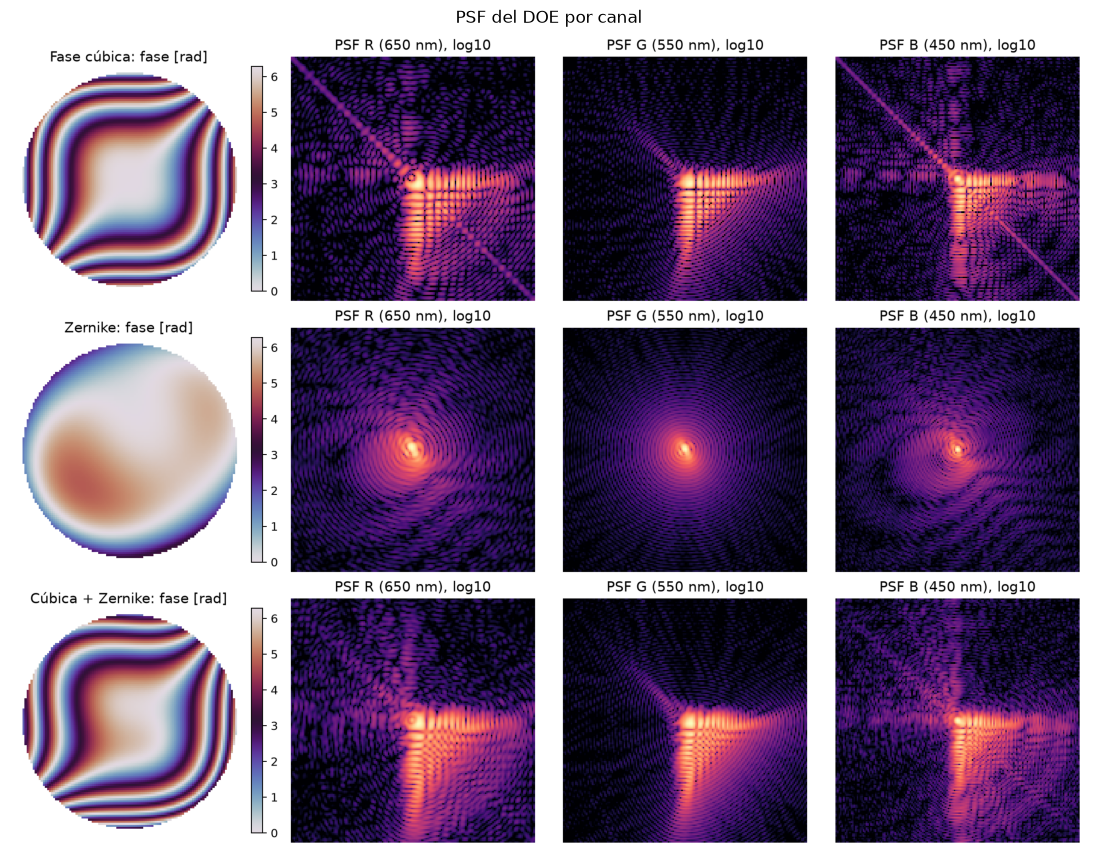

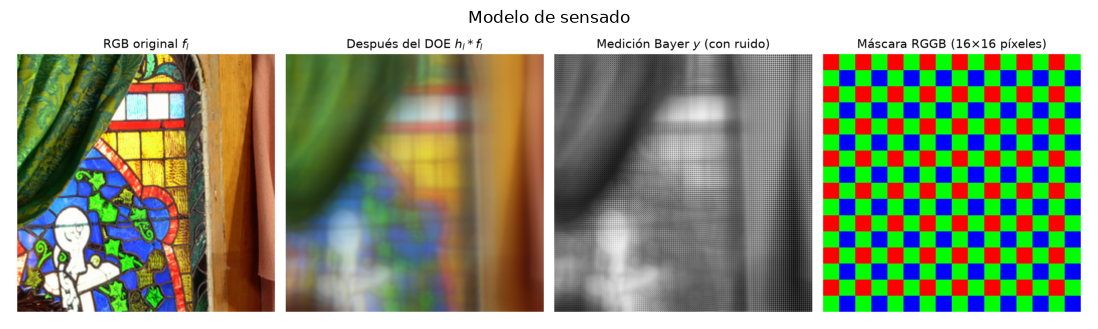

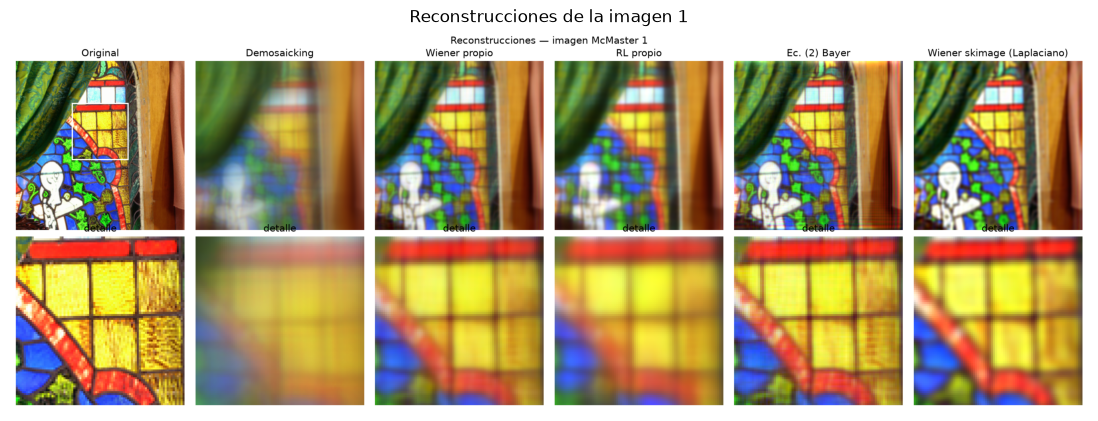

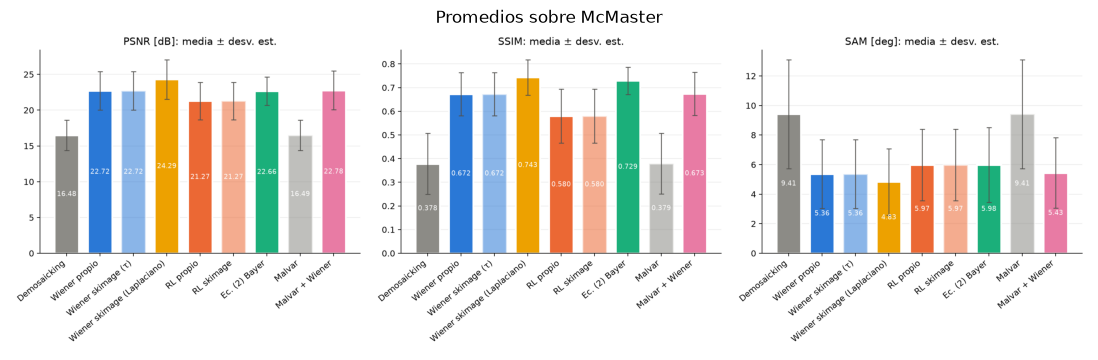

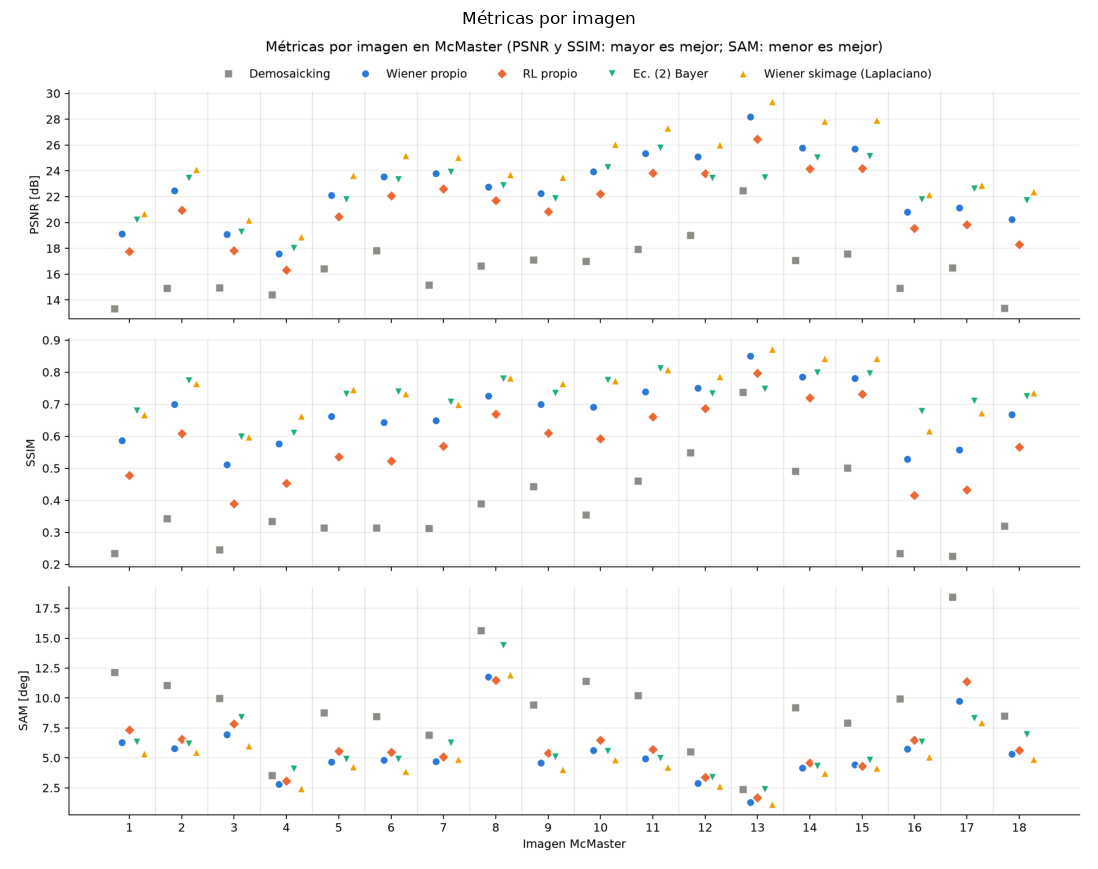

In [6]:
figures = [
    ('psf_doe.png', 'PSF del DOE por canal'),
    ('modelo_sensor.png', 'Modelo de sensado'),
    ('reconstruccion_ejemplo.png', 'Reconstrucciones de la imagen 1'),
    ('metricas_dataset.png', 'Promedios sobre McMaster'),
    ('metricas_por_imagen.png', 'Métricas por imagen'),
]
for filename, title in figures:
    image = plt.imread(TASK_DIR / 'Fig' / filename)
    height, width = image.shape[:2]
    fig, ax = plt.subplots(figsize=(14, 14 * height / width))
    ax.imshow(image)
    ax.set_title(title)
    ax.axis('off')
    plt.show()

## 8. Interpretacion

Wiener con tau constante y Richardson-Lucy propios mejoran PSNR, SSIM y SAM frente al demosaicking en las 18 imágenes de esta configuración. Tikhonov directo sobre Bayer mejora PSNR y SSIM en las 18, y SAM en 17. El Wiener de `skimage` con Laplaciano obtiene el mayor PSNR en las 18 imágenes y usa una regularización distinta. El informe `informe.pdf` relaciona estos resultados con la MTF y discute las limitaciones.
